In [47]:
%load_ext autoreload 
%autoreload 2
import sys; sys.path.append("..")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Prediction: Polynomial Regression and Learning Curves

**Degree 1** - Underfitting

A straight line cannot capture the quadratic relationship in the data. I expect training data and validation RMSE to plateau at relatively high values and remain close together, indicating high bias and a low variance.

**Degree 10** - Potential Overfitting

A degree-10 polynomial is flexible enough fit the underlying quadratic pattern but may also fit random noise in the training data. I expect training RMSE to be lower than validation RMSE, producing a noticeable gap between the learning curves and indicating higher variance.

**Expected best degree**: 2

The data is generated from a quadratic relationship, (y = 0.5x^2 + x + 2 + noise). Therefore, I expect degree 2 to achieve the lowest validation RMSE because it can represent the true underlying function without introducing unnecessary polynomial terms.

I expect degree 20 to have an even larger train-validation gap than degree 2, although its exact behavior will depend on the sample and numerical stability.

In [48]:
import numpy as np
import matplotlib.pyplot as plt 

np.random.seed(42)

m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)

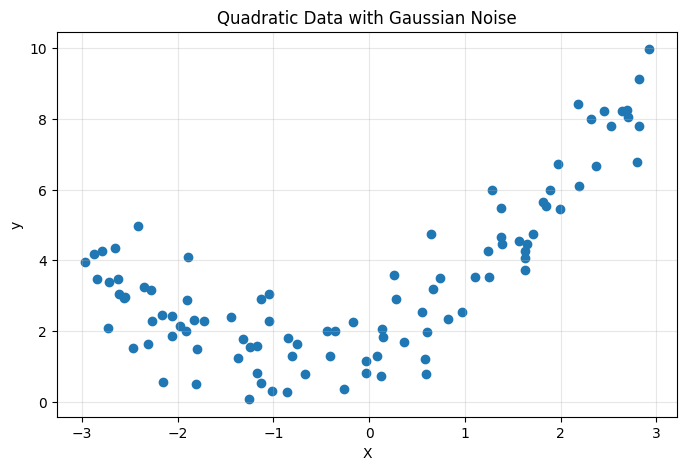

In [49]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Quadratic Data with Gaussian Noise")
plt.grid(True, alpha=0.3)
plt.show()

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=10
)

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

print("Training samples: ", len(X_train))
print("Validation samples: ", len(X_val))
print("Training RMSE baseline: ", rmse(y_train, np.full_like(y_train, np.mean(y_train))))

Training samples:  80
Validation samples:  20
Training RMSE baseline:  2.266807932421217


In [51]:
from src.models import normal_equation

theta_linear = normal_equation(X_train, y_train)
print("Linear theta: ", theta_linear.ravel())

Linear theta:  [3.62476388 0.82470152]


In [52]:
y_train_pred = np.c_[np.ones((len(X_train), 1)), X_train] @ theta_linear
y_val_pred = np.c_[np.ones((len(X_val), 1)), X_val] @ theta_linear

train_rmse_linear = rmse(y_train, y_train_pred)
val_rmse_linear = rmse(y_val, y_val_pred)

print(f"Training RMSE:   {train_rmse_linear:.4f}")
print(f"Validation RMSE: {val_rmse_linear:.4f}")

Training RMSE:   1.7207
Validation RMSE: 1.8180


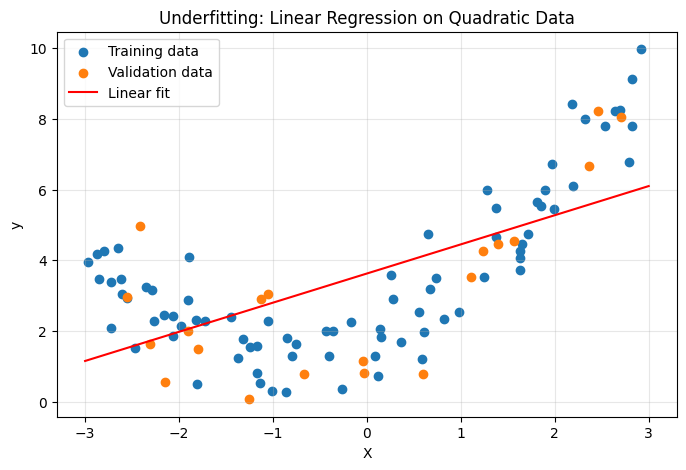

In [53]:
X_line = np.linspace(-3, 3, 200).reshape(-1, 1)
X_line_b = np.c_[np.ones((len(X_line), 1)), X_line]
y_line = X_line_b @ theta_linear

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label="Training data")
plt.scatter(X_val, y_val, label="Validation data")
plt.plot(X_line, y_line, color="red", label="Linear fit")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Underfitting: Linear Regression on Quadratic Data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [54]:
# Manual Quadratic Regression

X_train_poly = np.c_[X_train, X_train ** 2]
X_val_poly = np.c_[X_val, X_val ** 2]

theta_quad = normal_equation(X_train_poly, y_train)


print("Learned theta:", theta_quad.ravel())
print("True theta:   ", [2, 1, 0.5])

Learned theta: [1.85527661 0.93116462 0.55322027]
True theta:    [2, 1, 0.5]


In [55]:
y_train_quad = np.c_[
    np.ones((len(X_train_poly), 1)), X_train_poly
] @ theta_quad 

y_val_quad = np.c_[
    np.ones((len(X_val_poly), 1)), X_val_poly
] @ theta_quad

train_rmse_quad = rmse(y_train, y_train_quad)
val_rmse_quad = rmse(y_val, y_val_quad)

print(f"Training RMSE:   {train_rmse_quad:.4f}")
print(f"Validation RMSE: {val_rmse_quad:.4f}")

Training RMSE:   0.8334
Validation RMSE: 1.0581


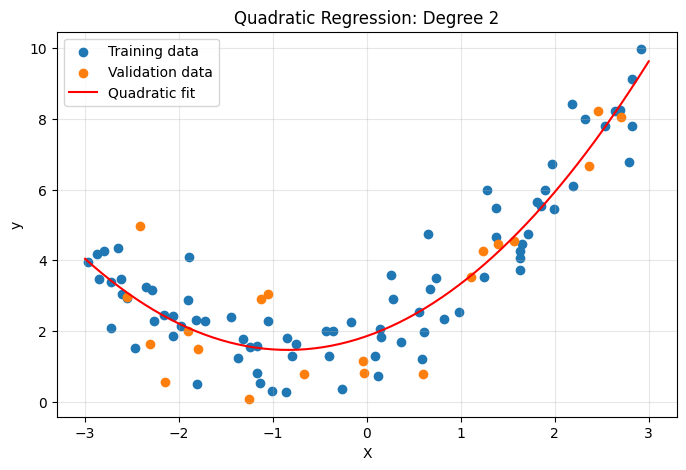

In [56]:
X_grid = np.linspace(-3, 3, 200).reshape(-1, 1)
X_grid_poly = np.c_[X_grid, X_grid ** 2]

X_grid_b = np.c_[
    np.ones((len(X_grid_poly), 1)), X_grid_poly
] 

y_grid = X_grid_b @ theta_quad

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label="Training data")
plt.scatter(X_val, y_val, label="Validation data")
plt.plot(X_grid, y_grid, color="red", label="Quadratic fit")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Quadratic Regression: Degree 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [57]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression(),
)

poly_model.fit(X_train, y_train.ravel())

sklearn_lr = poly_model.named_steps["linearregression"]

print("Manual theta:   ", theta_quad.ravel())
print("Sklearn intercept:", sklearn_lr.intercept_)
print("Sklearn coef:     ", sklearn_lr.coef_)

print("Sklearn train RMSE:",
      rmse(y_train.ravel(), poly_model.predict(X_train)))

print("Sklearn val RMSE:  ",
      rmse(y_val.ravel(), poly_model.predict(X_val)))

Manual theta:    [1.85527661 0.93116462 0.55322027]
Sklearn intercept: 1.8552766097802154
Sklearn coef:      [0.93116462 0.55322027]
Sklearn train RMSE: 0.8334191752563737
Sklearn val RMSE:   1.0580515251368285


In [59]:
from sklearn.pipeline import make_pipeline

degrees = [1, 2, 10, 20]
degree_results = {}

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression(),
    )

    model.fit(X_train, y_train.ravel())

    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)

    train_error = rmse(y_train.ravel(), y_train_pred)
    val_error = rmse(y_val.ravel(), y_val_pred)

    degree_results[degree] = {
        "model": model,
        "train_rmse": train_error,
        "val_rmse": val_error,
    }

    print(
        f"Degree {degree:2d} | "
        f"Train RMSE: {train_error:.4f} | "
        f"Validation RMSE: {val_error:.4f}"
    )

Degree  1 | Train RMSE: 1.7207 | Validation RMSE: 1.8180
Degree  2 | Train RMSE: 0.8334 | Validation RMSE: 1.0581
Degree 10 | Train RMSE: 0.8034 | Validation RMSE: 1.0930
Degree 20 | Train RMSE: 0.7424 | Validation RMSE: 1.1786


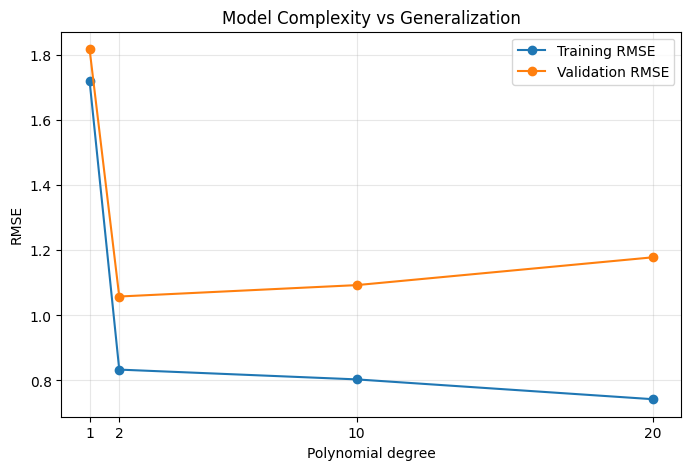

In [64]:
train_errors = [
    degree_results[d]["train_rmse"] for d in degrees
]

val_errors = [
    degree_results[d]["val_rmse"] for d in degrees
]

plt.figure(figsize=(8, 5))
plt.plot(degrees, train_errors, "o-", label="Training RMSE")
plt.plot(degrees, val_errors, "o-", label="Validation RMSE")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE")
plt.title("Model Complexity vs Generalization")
plt.xticks(degrees)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Model Complexity vs. Generalization

### Degree 1 — Underfitting

- **Training RMSE:** ≈ 1.72
- **Validation RMSE:** ≈ 1.82

Both errors are high and close together. The model is too simple to capture the underlying quadratic pattern, resulting in **high bias**.

### Degree 2 — Best Generalization

- **Training RMSE:** ≈ 0.83
- **Validation RMSE:** ≈ 1.06

The model captures the underlying quadratic relationship with relatively little unnecessary complexity. It achieves the lowest validation RMSE among the degrees tested.

### Degree 10 — Beginning to Overfit

- **Training RMSE:** ≈ 0.80
- **Validation RMSE:** ≈ 1.09

Training error decreases slightly, but validation error increases compared with degree 2. The additional flexibility helps the model fit the training data without improving generalization, indicating **overfitting**.

### Degree 20 — Greater Overfitting

- **Training RMSE:** ≈ 0.74
- **Validation RMSE:** ≈ 1.18

The model fits the training data better, but predicts unseen observations worse than degree 2. The increasing gap between training and validation errors indicates higher variance.

### Conclusion

Increasing polynomial degree makes the model more flexible, generally reducing training error. However, excessive complexity can cause overfitting and increase validation error. For this dataset and train-validation split, **degree 2 provides the best generalization** among the tested models.

In [78]:
def plot_learning_curves_manual(
        model, X_train, y_train, X_val, y_val
):
    train_errors = []
    val_errors = []

    for n in range(2, len(X_train) + 1):
        model.fit(X_train[:n], y_train[:n].ravel())

        y_train_pred = model.predict(X_train[:n])
        y_val_pred = model.predict(X_val)

        train_errors.append(
            rmse(y_train[:n].ravel(), y_train_pred)
        )

        val_errors.append(
            rmse(y_val.ravel(), y_val_pred)
        )

    plt.figure(figsize=(8, 5))
    plt.plot(
        range(2, len(X_train) + 1),
        train_errors,
        label="Trainig RMSE",
    )
    plt.plot(
        range(2, len(X_train) + 1),
        val_errors,
        label="Validation RMSE",
    )
    plt.xlabel("Number of training samples")
    plt.ylabel("RMSE")
    plt.title("Learning Curves")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    return train_errors, val_errors

Learning curves: degree 1


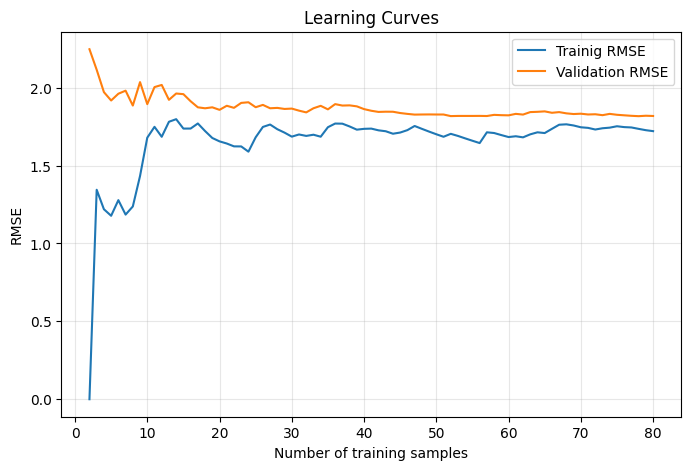

Learning curves: degree 2


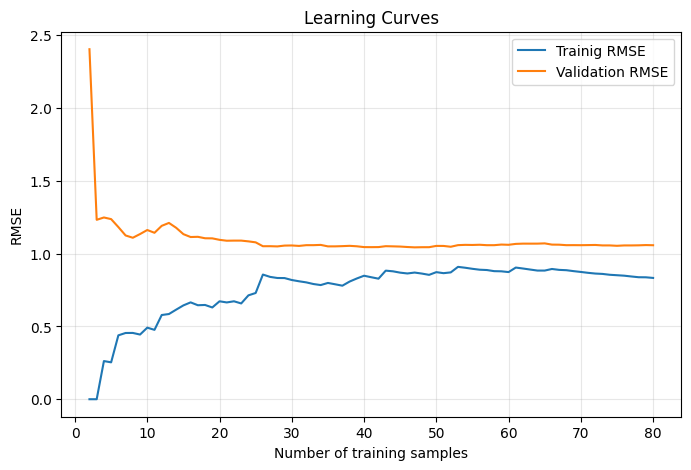

Learning curves: degree 10


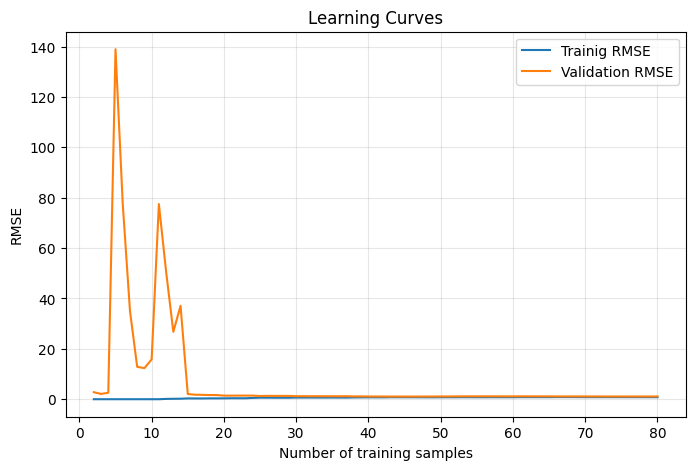

In [80]:
for degree in [1, 2, 10]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression(),
    )

    print(f"Learning curves: degree {degree}")

    train_errors, val_errors = plot_learning_curves_manual(
        model, X_train, y_train, X_val, y_val
    )

## Interpreting the Learning Curves

### 1. Why does training error start near zero with very few samples?

With only a few training samples, a sufficiently flexible polynomial model can fit those observations almost perfectly. For example, a degree-10 polynomial has enough flexibility to interpolate a small number of distinct data points.

However, fitting a few observations perfectly does not mean the model has learned the underlying relationship. It may produce wildly inaccurate predictions on unseen data, resulting in a very high validation RMSE.

As we add more training samples, fitting every observation perfectly becomes harder, so training RMSE generally increases.

### 2. Why does degree 1 plateau at a high error, with the curves close together?

A degree-1 model fits a straight line, but our data follows an underlying quadratic relationship:

\[
y = 0.5x^2 + x + 2 + noise
\]

A straight line cannot capture this curvature, regardless of how many training samples we provide. Consequently, training and validation RMSE tend to plateau at relatively high values.

The two curves remain close because the model is too simple to fit the training data particularly well in the first place. This behavior indicates **high bias and underfitting**.

Adding more data alone cannot fix this limitation; we need a model capable of representing the underlying relationship.

### 3. Why does degree 10 leave a gap between the curves?

A degree-10 polynomial is much more flexible than a straight line. It can fit the training observations closely, including patterns caused by random noise.

This can produce low training RMSE but higher validation RMSE because some patterns learned from the training data do not generalize to unseen observations.

The gap between the curves indicates a generalization problem associated with **high variance and overfitting**. With more training data, the gap may shrink as the fitted model becomes more stable, although the curves need not decrease smoothly.

In [83]:
# scikit-learn's learning_curve()

from sklearn.model_selection import learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

train_sizes = np.linspace(0.01, 1.0, 40)

sklearn_learning_results = {}

for degree in [1, 2, 10]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression(),
    )

    sizes, train_scores, val_scores = learning_curve(
        model,
        X,
        y.ravel(),
        train_sizes=train_sizes,
        cv=5,
        scoring="neg_root_mean_squared_error",
    )

    # Scikit-learn negates RMSE, so convert scores back.
    train_rmse = -train_scores.mean(axis=1)
    val_rmse = -val_scores.mean(axis=1)

    sklearn_learning_results[degree] = {
        "sizes": sizes,
        "train_rmse": train_rmse,
        "val_rmse": val_rmse,
    }

    print(
        f"Degree {degree}: "
        f"Train RMSE = {train_rmse[-1]:.4f}, "
        f"Validation RMSE = {val_rmse[-1]:.4f}"
    )


Degree 1: Train RMSE = 1.7380, Validation RMSE = 1.7448
Degree 2: Train RMSE = 0.8766, Validation RMSE = 0.9155
Degree 10: Train RMSE = 0.8418, Validation RMSE = 1.0294


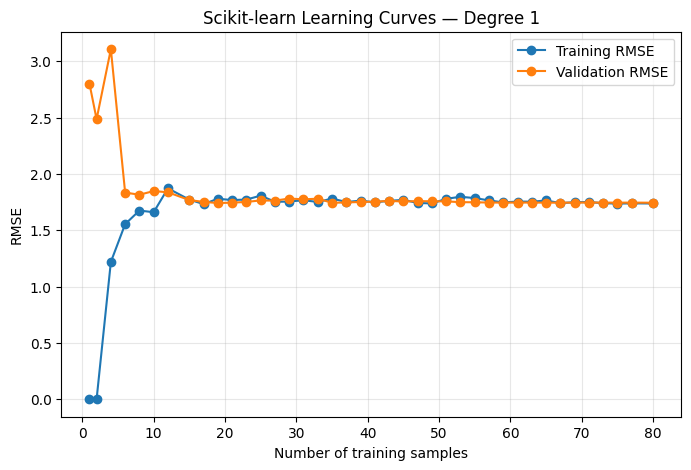

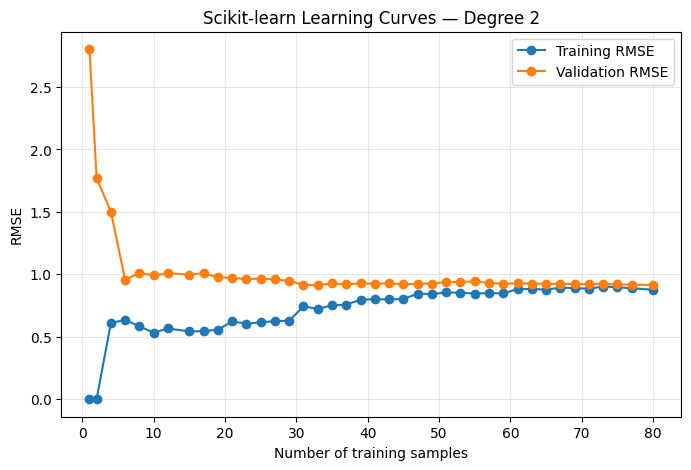

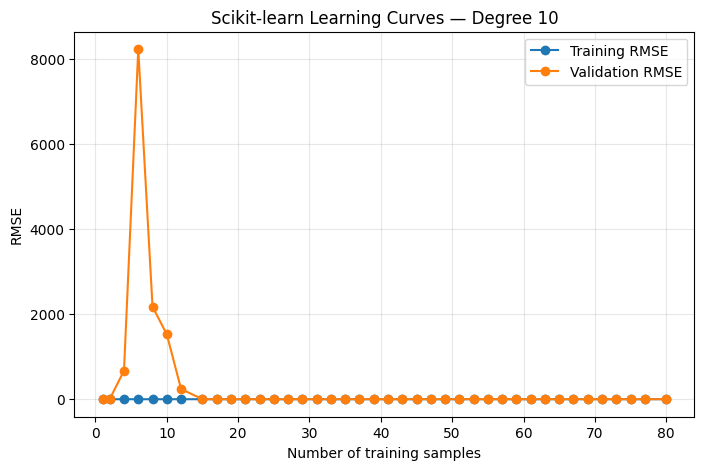

In [84]:

for degree, results in sklearn_learning_results.items():
    sizes = results["sizes"]
    train_rmse = results["train_rmse"]
    val_rmse = results["val_rmse"]

    plt.figure(figsize=(8, 5))

    plt.plot(sizes, train_rmse, "o-", label="Training RMSE")
    plt.plot(sizes, val_rmse, "o-", label="Validation RMSE")

    plt.xlabel("Number of training samples")
    plt.ylabel("RMSE")
    plt.title(f"Scikit-learn Learning Curves — Degree {degree}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


## Bias–Variance Trade-off

| Polynomial degree | Bias | Variance | Expected behavior |
|---|---|---|---|
| 1 | High | Low | Underfits because a straight line cannot represent the quadratic relationship. Training and validation errors remain relatively high and close together. |
| 2 | Low | Low to moderate | Captures the underlying quadratic pattern without unnecessary complexity. Training and validation errors are both relatively low. |
| 20 | Low | High | Has enough flexibility to fit training-specific noise. Training error decreases, but validation error increases, indicating overfitting. |

**Conclusion:** Increasing model complexity can reduce bias, but excessive complexity can increase variance. The goal is to find a model that captures the underlying relationship while generalizing well to unseen data. In this experiment, degree 2 provides the best balance.

In [ ]:
degree = 300

model_300 = make_pipeline(
    PolynomialFeatures(degree=degree, include_bias=False),
    LinearRegression(),
)

model_300.fit(X_train, y_train.ravel())

y_train_pred_300 = model_300.predict(X_train)
y_val_pred_300 = model_300.predict(X_val)

print(f"Training RMSE:   {rmse(y_train.ravel(), y_train_pred_300):.4f}")
print(f"Validation RMSE: {rmse(y_val.ravel(), y_val_pred_300):.4f}")


Training RMSE:   1.9505
Validation RMSE: 2.3887


## Degree 300: Numerical Instability

A degree-300 polynomial creates features with extremely different magnitudes. Since the inputs range from -3 to 3, large powers can become enormous, while powers of inputs with absolute values below 1 can become extremely small.

This makes the design matrix badly conditioned. The SVD-based pseudoinverse uses a numerical tolerance when deciding which singular values to retain, potentially discarding small singular values and producing an inaccurate parameter estimate.

Consequently, the degree-300 model can perform worse than a simple linear model, even on the training data. This is a numerical-stability problem, distinct from ordinary overfitting.

Possible remedies include scaling the input features, using a better-conditioned polynomial basis, and applying regularization. Scaling alone does not guarantee that a degree-300 polynomial will be numerically stable.


In [92]:
# Migration Check:

from src.models import make_polynomial_model
from src.visualization import plot_learning_curves


model_2 = make_polynomial_model(2)
model_2.fit(X_train, y_train.ravel())

train_pred = model_2.predict(X_train)
val_pred = model_2.predict(X_val)

print(f"Training RMSE:   {rmse(y_train.ravel(), train_pred):.4f}")
print(f"Validation RMSE: {rmse(y_val.ravel(), val_pred):.4f}")


Training RMSE:   0.8334
Validation RMSE: 1.0581


Degree 1


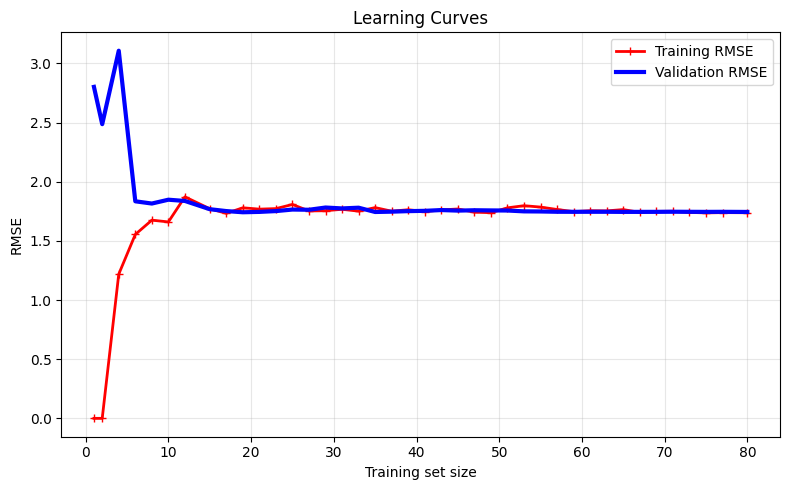

Degree 2


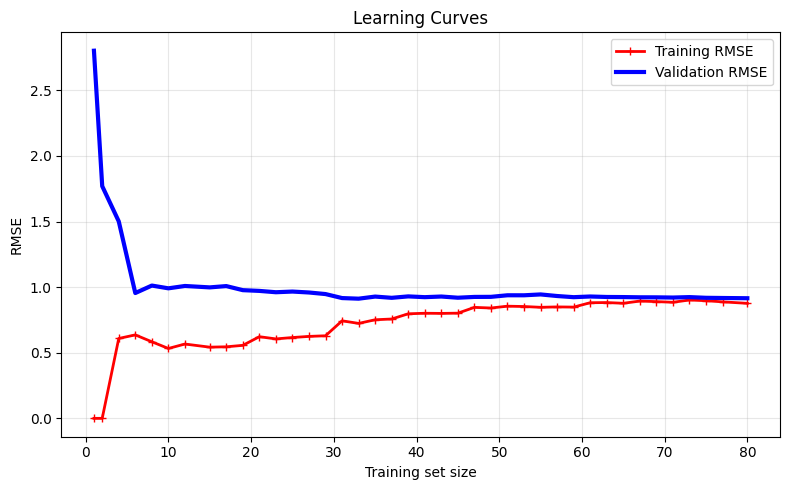

Degree 10


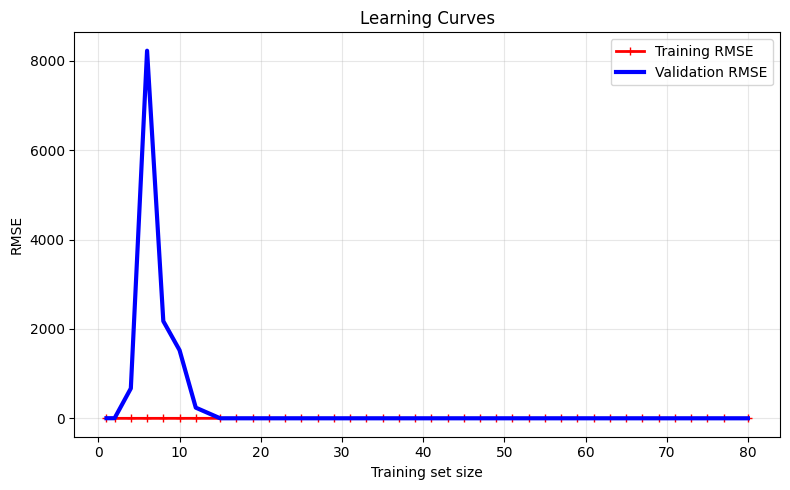

In [93]:

for degree in [1, 2, 10]:
    print(f"Degree {degree}")
    model = make_polynomial_model(degree)
    plot_learning_curves(model, X, y)
